In [1]:
import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
mpl.rcParams['svg.fonttype'] = 'none'   # keeps text editable in Illustrator
plt.rcParams['svg.fonttype'] = 'none'

import seaborn as sns

from scipy.stats import ttest_ind, f_oneway
from scipy.stats import pearsonr
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

from adjustText import adjust_text




In [9]:
# import the spreadsheet of z-scored behavioral metrics

df = pd.read_excel(r"D:\ACW\behavior\analysis\excel\severity_classification_metrics_zscores_n44_09.16.26.xlsx")

#display(df)

animal_ids = df["animal"]


# clean up for PCA

X = df.drop(columns=["severity","animal"])

df["sex"] = df["animal"].str.extract(r"_(m|f)\d")[0].map({"m": "male", "f": "female"})

X.columns = X.columns.str.replace('\xa0', ' ', regex=False)
X.columns = (
    X.columns
    .str.replace('\xa0', ' ', regex=False)
    .str.strip()
)

X.columns = X.columns.str.replace('\xa0', ' ', regex=False).str.strip()

X

,days for 10 infusions,intake,avg infusion latency,consistency,seeking,motivation,extinction lever presses,reinstatement
0,0.1397,-0.0181,-0.2373,-0.0460,0.1262,0.2382,0.2574,-0.5836
1,-0.2702,0.0531,-0.3817,-0.3038,-0.1499,-0.3469,-0.3870,-0.4176
2,0.1397,-0.0324,-0.0025,0.1749,0.2445,0.1746,1.6298,-0.1331
3,0.1397,0.1029,0.2416,0.2118,0.6241,-0.4105,0.7109,0.5545
4,0.1397,-0.7517,-0.3506,-1.0404,-0.4654,-0.4487,-0.2438,-0.0857
5,0.9596,0.7012,1.4791,1.1325,1.0431,-0.0543,0.3529,-0.8207
6,0.9596,1.1356,0.6950,0.6537,0.5206,-0.4868,-0.4228,-1.1527
7,0.5497,0.9006,0.9494,0.8010,0.9396,-0.0671,-0.2080,-0.3228
8,-0.2702,1.3564,0.4605,0.9483,4.3067,-0.1561,2.4771,-1.1289
9,-0.6801,-1.1363,-1.2418,-1.2245,-0.9535,-0.4105,-0.7212,-0.6310


,PC1,PC2,sex,animal,severity,severity_score
0,0.079777,-0.048863,male,ACW_coh1a_IT_m1,moderate,-0.1235
1,0.690563,-0.233867,male,ACW_coh1a_IT_m2,low,-2.2040
2,-0.756047,0.479687,male,ACW_coh1a_IT_m3,high,2.1955
3,-0.812393,0.018563,male,ACW_coh1b_PT_m1,high,2.1750
4,1.323054,-0.035148,male,ACW_coh1b_PT_m2,low,-3.2466
5,-1.893904,-1.438583,female,ACW_coh1c_IT_f1,high,4.7934
6,-0.893831,-1.905775,female,ACW_coh1c_IT_f2,high,1.9022
7,-1.438479,-1.086414,female,ACW_coh1c_IT_f3,high,3.5424
8,-3.346574,-0.382200,female,ACW_coh1c_PT_f3,high,7.9938
9,2.571214,0.346856,male,ACW_coh2a_IT_m1,low,-6.9989


r = -0.990
p = 3.544e-37


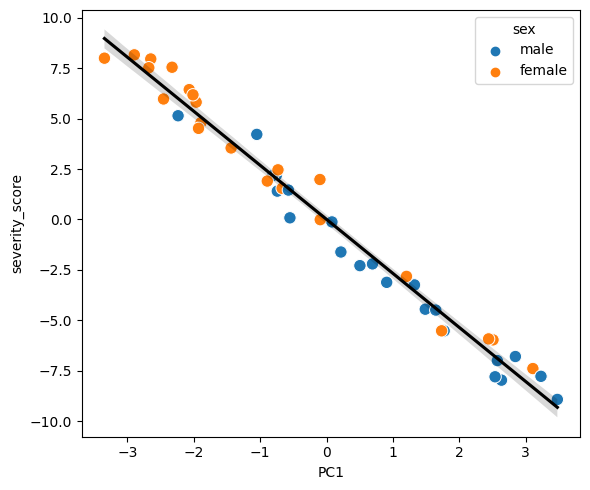

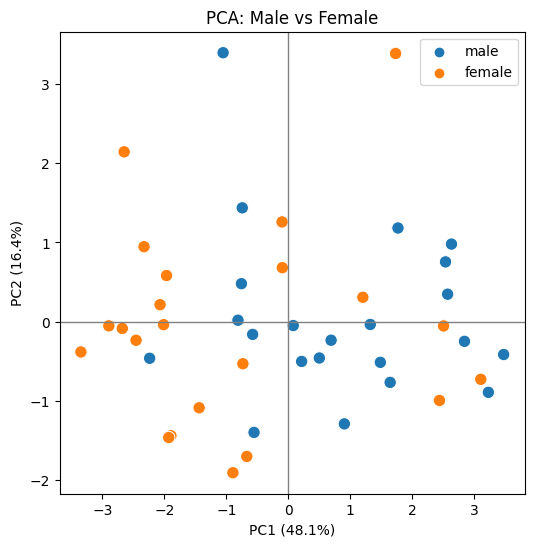

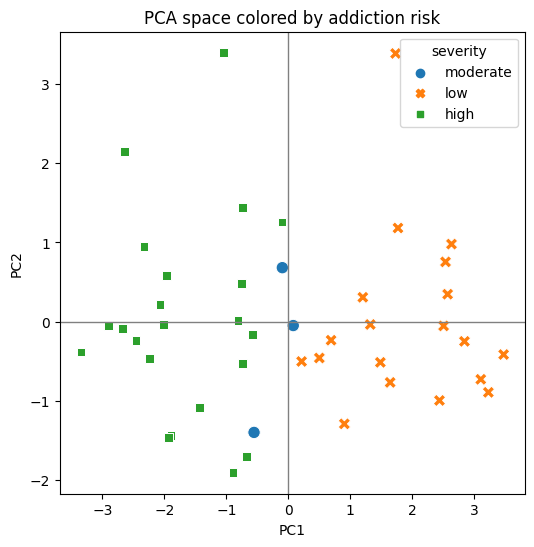


SEX RESULTS


,PC,t,p,p_fdr
0,PC1,3.260669,0.002209,0.011044
1,PC2,0.304759,0.762055,0.930844
2,PC3,-2.410020,0.020410,0.051025
3,PC4,1.651041,0.106189,0.176982
4,PC5,0.087305,0.930844,0.930844



SEVERITY RESULTS


,PC,F,p,p_fdr
0,PC1,78.304573,9.954620e-15,4.977310e-14
1,PC2,0.086089,9.176776e-01,9.176776e-01
2,PC3,0.293633,7.471046e-01,9.176776e-01
3,PC4,0.922297,4.056956e-01,9.176776e-01
4,PC5,0.093622,9.108213e-01,9.176776e-01


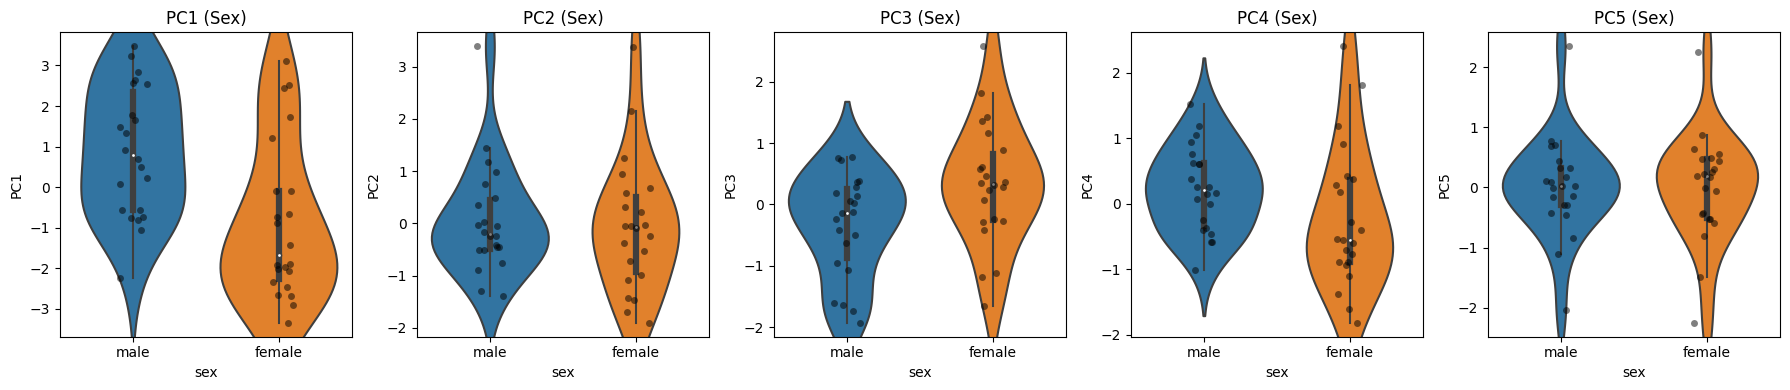

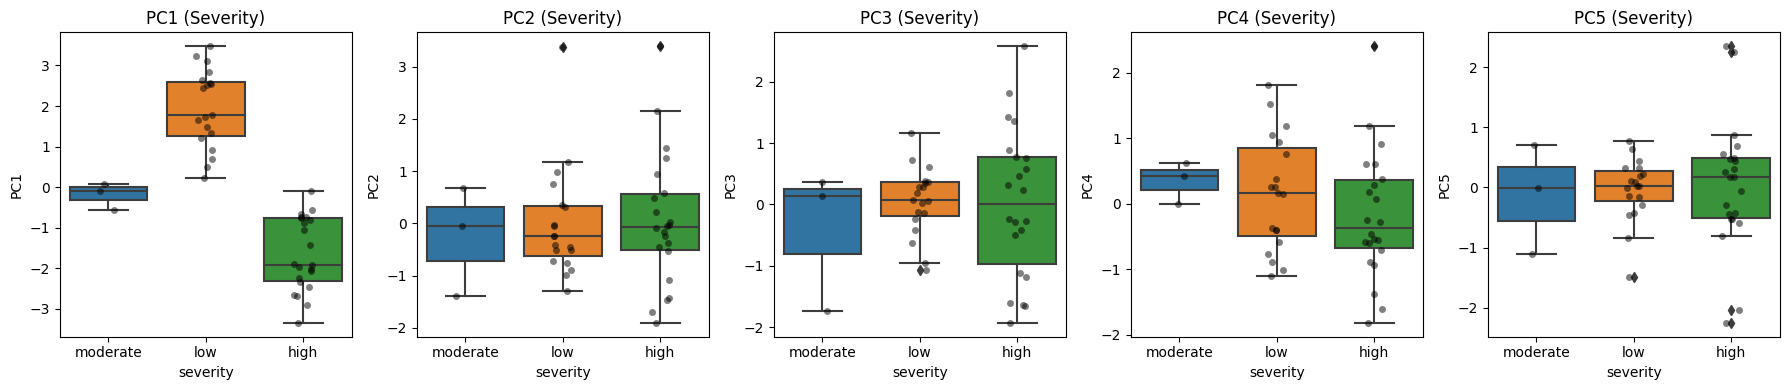

                            OLS Regression Results                            
Dep. Variable:                    PC1   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.790
Method:                 Least Squares   F-statistic:                     33.35
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           6.49e-13
Time:                        17:13:17   Log-Likelihood:                -54.517
No. Observations:                  44   AIC:                             121.0
Df Residuals:                      38   BIC:                             131.7
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

In [10]:
# run principal components analysis and assemble dataframe for further analysis

pca = PCA()
scores = pca.fit_transform(X)


pc_df = pd.DataFrame(
    scores[:, :2],
    columns=["PC1", "PC2"]
)

pc_df["sex"] = df["sex"].values
pc_df["animal"] = df["animal"].values
pc_df["severity"] = df["severity"].values
pc_df["severity_score"] = X.sum(axis=1)


display(pc_df)
pc_df.to_csv("pca_scores.csv", index=False)
pc_df["severity"].value_counts()


# PC1 is similar to the cumulative z-score used for risk classification

r, p = pearsonr(
    pc_df["PC1"],
    pc_df["severity_score"]
)

print(f"r = {r:.3f}")
print(f"p = {p:.3e}")


# visualize relationship between sex, risk classification, and PC1, 2

plt.figure(figsize=(6,5))

sns.scatterplot(
    data=pc_df,
    x="PC1",
    y="severity_score",
    hue="sex",
    s=80
)

sns.regplot(
    data=pc_df,
    x="PC1",
    y="severity_score",
    scatter=False,
    color="black"
)

plt.tight_layout()
plt.show()

########
plt.figure(figsize=(6,6))

sns.scatterplot(
    data=pc_df,
    x="PC1",
    y="PC2",
    hue="sex",
    s=80
)

plt.axhline(0, color="gray", lw=1)
plt.axvline(0, color="gray", lw=1)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")

plt.title("PCA: Male vs Female")
plt.legend()
plt.show()



plt.figure(figsize=(6,6))

sns.scatterplot(
    data=pc_df,
    x="PC1",
    y="PC2",
    hue="severity",
    style="severity",
    s=80
)

plt.axhline(0,color="gray",lw=1)
plt.axvline(0,color="gray",lw=1)

plt.title("PCA space colored by addiction risk")
plt.show()


#### analysis of sex and risk in PCA

# -----------------------------
# Build PCA dataframe
# -----------------------------
pc_df = pd.DataFrame(
    scores[:, :5],
    columns=["PC1","PC2","PC3","PC4","PC5"]
)

pc_df["sex"] = df["sex"].values
pc_df["severity"] = df["severity"].values

pcs = ["PC1","PC2","PC3","PC4","PC5"]

# -----------------------------
# SEX: t-tests
# -----------------------------
sex_results = []

for pc in pcs:
    male = pc_df[pc_df["sex"]=="male"][pc]
    female = pc_df[pc_df["sex"]=="female"][pc]

    t, p = ttest_ind(male, female)

    sex_results.append([pc, t, p])

sex_df = pd.DataFrame(sex_results, columns=["PC","t","p"])
sex_df["p_fdr"] = multipletests(sex_df["p"], method="fdr_bh")[1]

print("\nSEX RESULTS")
display(sex_df)

# -----------------------------
# SEVERITY: ANOVA
# -----------------------------
sev_results = []

for pc in pcs:
    groups = [
        pc_df[pc_df["severity"]=="low"][pc],
        pc_df[pc_df["severity"]=="moderate"][pc],
        pc_df[pc_df["severity"]=="high"][pc]
    ]

    F, p = f_oneway(*groups)

    sev_results.append([pc, F, p])

sev_df = pd.DataFrame(sev_results, columns=["PC","F","p"])
sev_df["p_fdr"] = multipletests(sev_df["p"], method="fdr_bh")[1]

print("\nSEVERITY RESULTS")
display(sev_df)

# -----------------------------
# PLOTS: SEX (violin)
# -----------------------------
fig, axes = plt.subplots(1, 5, figsize=(18,4), sharey=False)

for i, pc in enumerate(pcs):
    sns.violinplot(
        data=pc_df,
        x="sex",
        y=pc,
        ax=axes[i]
    )
    sns.stripplot(
        data=pc_df,
        x="sex",
        y=pc,
        color="black",
        alpha=0.5,
        ax=axes[i]
    )
    axes[i].set_title(f"{pc} (Sex)")

plt.tight_layout()
plt.show()

# -----------------------------
# PLOTS: SEVERITY (box)
# -----------------------------
fig, axes = plt.subplots(1, 5, figsize=(18,4), sharey=False)

for i, pc in enumerate(pcs):
    sns.boxplot(
        data=pc_df,
        x="severity",
        y=pc,
        ax=axes[i]
    )
    sns.stripplot(
        data=pc_df,
        x="severity",
        y=pc,
        color="black",
        alpha=0.5,
        ax=axes[i]
    )
    axes[i].set_title(f"{pc} (Severity)")

plt.tight_layout()
plt.show()




# ordinary least squares linear regression to examine contribution of sex and risk class to PC1, 2


linear_model = smf.ols("PC1 ~ C(sex) * C(severity)", data=pc_df).fit()
print(linear_model.summary())
print(linear_model.pvalues)

smf.ols("PC2 ~ C(sex) * C(severity)", data=pc_df).fit().summary()




# logistic model to test if sex predicts the probability of being in the high severity group

pc_df["high"] = (pc_df["severity"] == "high").astype(int)

model = smf.logit("high ~ C(sex)", data=pc_df).fit()

print(model.summary())
print(np.exp(model.params))

[0.48090736 0.16424541 0.11695567 0.10333585 0.09014474 0.02315083
 0.01340682 0.00785333]
[0.48090736 0.64515277 0.76210844 0.86544429 0.95558903 0.97873985
 0.99214667 1.        ]


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
intake,0.463,-0.194,-0.003,0.148,-0.159,0.464,0.639,0.278
consistency,0.453,-0.161,-0.356,0.131,-0.023,-0.201,0.063,-0.762
avg infusion latency,0.435,-0.188,-0.416,0.011,-0.072,-0.380,-0.364,0.566
seeking,0.364,-0.071,0.489,0.443,0.270,0.297,-0.513,-0.049
extinction lever presses,0.358,0.337,0.481,-0.158,0.257,-0.567,0.331,0.059
reinstatement,0.263,0.415,0.172,-0.275,-0.751,0.140,-0.249,-0.093
motivation,0.204,0.566,-0.399,-0.284,0.492,0.386,-0.077,0.016
days for 10 infusions,0.140,-0.538,0.203,-0.764,0.155,0.146,-0.119,-0.082


,PC,eigenvalue,% variance,cumulative %
0,PC1,3.847,48.091,48.091
1,PC2,1.314,16.425,64.515
2,PC3,0.936,11.696,76.211
3,PC4,0.827,10.334,86.544
4,PC5,0.721,9.014,95.559
5,PC6,0.185,2.315,97.874
6,PC7,0.107,1.341,99.215
7,PC8,0.063,0.785,100.000


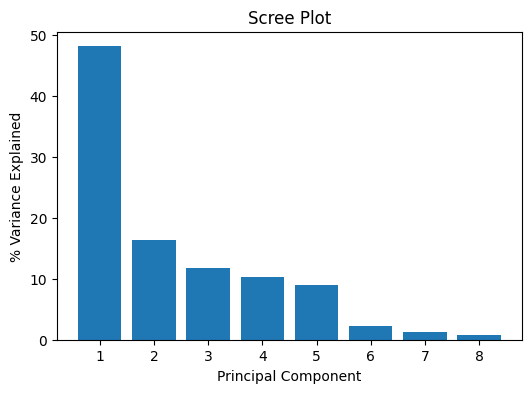

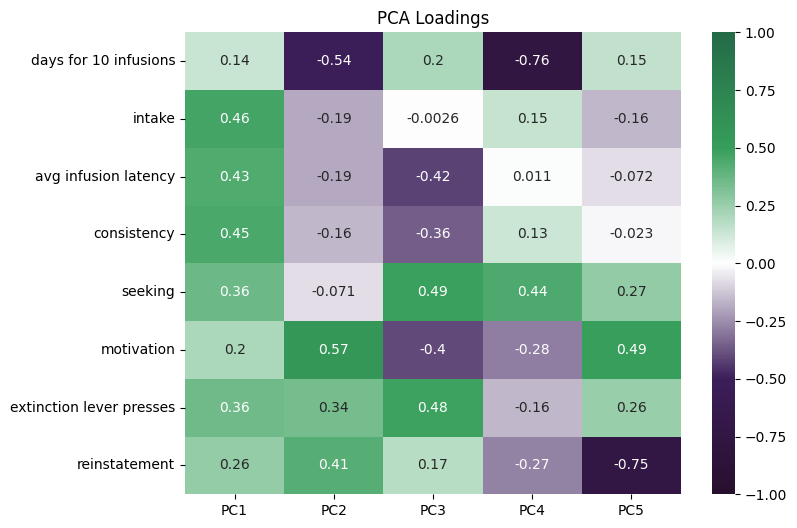

,PC1,PC2,PC3,PC4,PC5
days for 10 infusions,0.27,-0.62,0.20,-0.69,0.13
intake,0.91,-0.22,-0.00,0.13,-0.13
avg infusion latency,0.85,-0.22,-0.40,0.01,-0.06
consistency,0.89,-0.18,-0.34,0.12,-0.02
seeking,0.71,-0.08,0.47,0.40,0.23
motivation,0.40,0.65,-0.39,-0.26,0.42
extinction lever presses,0.70,0.39,0.47,-0.14,0.22
reinstatement,0.52,0.48,0.17,-0.25,-0.64


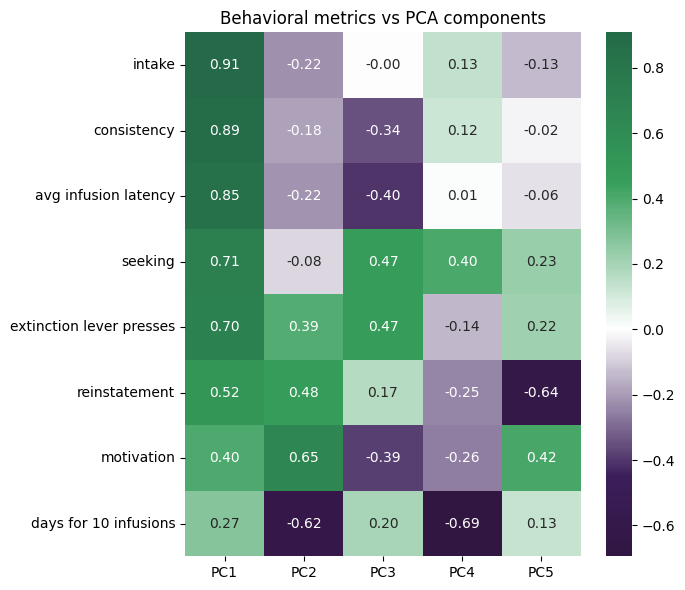

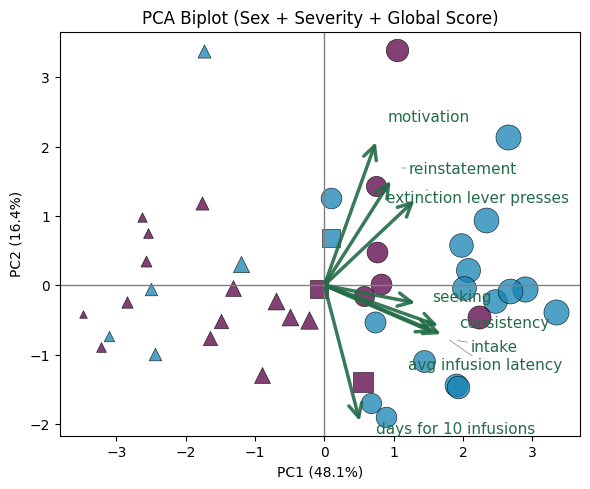

In [11]:



# Variance explained by each PC
print(pca.explained_variance_ratio_)

# Cumulative variance explained
print(np.cumsum(pca.explained_variance_ratio_))

loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=[f"PC{i+1}" for i in range(len(X.columns))]
)
scores[:, 0] *= -1
loadings["PC1"] *= -1
loadings_sorted=loadings.sort_values("PC1", ascending=False)
display(loadings_sorted.round(3))


#####################
# summary table
# eigenvalues
eigvals = pca.explained_variance_

# variance ratio
var_ratio = pca.explained_variance_ratio_

# cumulative variance
cum_var = np.cumsum(var_ratio)

# build dataframe
pca_summary = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(eigvals))],
    "eigenvalue": eigvals,
    "% variance": var_ratio * 100,
    "cumulative %": cum_var * 100
})

display(pca_summary.round(3))
#####################

# --- Custom diverging colormap ---
deep_green = np.array([36, 106, 72]) / 255
green = np.array([54, 158, 90]) / 255
purple = np.array([60, 30, 90]) / 255
white = np.array([1, 1, 1])
deep_redpurple = np.array([40, 15, 45]) / 255

custom_cmap = LinearSegmentedColormap.from_list(
    "GreenPurple",
    [deep_redpurple, purple, white, green, deep_green],
    N=256
)


var = pca.explained_variance_ratio_

plt.figure(figsize=(6,4))
plt.bar(range(1, len(var)+1), var*100)
plt.xlabel("Principal Component")
plt.ylabel("% Variance Explained")
plt.title("Scree Plot")
plt.show()

plt.figure(figsize=(8,6))

sns.heatmap(
    loadings.iloc[:,0:5],
    annot=True,
    cmap=custom_cmap,
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("PCA Loadings")
plt.show()



#######################
# how much does each behavioral metric contribute to each PC?

# clean column names
X.columns = X.columns.str.replace('\xa0', ' ', regex=False).str.strip()

pcs = pc_df[["PC1","PC2","PC3","PC4","PC5"]]#,"PC6","PC7","PC8"]]

# combine raw + PCs
combined = pd.concat([X, pcs], axis=1)

# correlation: metrics vs PCs
metric_pc_corr = combined.corr().loc[
    X.columns,
    ["PC1","PC2","PC3","PC4","PC5"]#,"PC6","PC7","PC8"]
]

display(metric_pc_corr.round(2))
metric_pc_corr_sorted = metric_pc_corr.sort_values("PC1", ascending=False)

# heatmap
plt.figure(figsize=(7,6))
sns.heatmap(
    metric_pc_corr_sorted,
    annot=True,
    cmap=custom_cmap,
    center=0,
    fmt=".2f"
)

plt.title("Behavioral metrics vs PCA components")
plt.tight_layout()
plt.show()

#####################




def biplot(scores, loadings, labels, metadata, save_path, pc1=0, pc2=1):

    fig, ax = plt.subplots(figsize=(6,6))

    # -----------------------
    # COLORS (SEX)
    # -----------------------
    sex_colors = {
        "male": (90/255, 0/255, 70/255),
        "female": (20/255, 130/255, 180/255)
    }

    green = (36/255, 108/255, 72/255)

    # -----------------------
    # SHAPES (SEVERITY CATEGORY)
    # -----------------------
    severity_markers = {
        "low": "^",
        "moderate": "s",
        "high": "o"
    }

    # -----------------------
    # SIZE SCALING (SEVERITY SCORE)
    # -----------------------
    sev = metadata["severity_score"].values

    sizes = 30 + 300 * (sev - np.min(sev)) / (np.max(sev) - np.min(sev))

    # -----------------------
    # SCORE PLOT
    # -----------------------
    for i in range(len(scores)):
        ax.scatter(
            scores[i, pc1],
            scores[i, pc2],
            color=sex_colors.get(metadata["sex"].iloc[i], "gray"),
            marker=severity_markers.get(metadata["severity"].iloc[i], "x"),
            s=sizes[i],
            alpha=0.75,
            edgecolor="black",
            linewidth=0.5
        )

    # -----------------------
    # SCALE LOADINGS
    # -----------------------
    xs = scores[:, pc1]
    ys = scores[:, pc2]

    scale = 0.7 * min(
        np.max(xs) - np.min(xs),
        np.max(ys) - np.min(ys)
    )

    # -----------------------
    # LOADINGS (ARROWS + LABELS)
    # -----------------------
    texts = []

    for i, var in enumerate(labels):

        x_end = loadings[i, pc1] * scale
        y_end = loadings[i, pc2] * scale

        # thicker arrow with better control
        ax.annotate(
            "",
            xy=(x_end, y_end),
            xytext=(0, 0),
            arrowprops=dict(
                arrowstyle="->",
                color=green,
                lw=2.5,
                mutation_scale=24,
                alpha=0.9
            )
        )

        # label (to be adjusted later)
        texts.append(
            ax.text(
                x_end * 1.1,
                y_end * 1.1,
                var,
                color=green,
                fontsize=11
            )
        )

    # -----------------------
    # AUTOMATIC LABEL REPULSION
    # -----------------------
    adjust_text(
        texts,
        ax=ax,
        arrowprops=dict(arrowstyle="-", color="gray", lw=0.5)
    )

    # -----------------------
    # AXES
    # -----------------------
    ax.axhline(0, color='gray', lw=1)
    ax.axvline(0, color='gray', lw=1)

    ax.set_xlabel(f"PC{pc1+1} ({pca.explained_variance_ratio_[pc1]*100:.1f}%)")
    ax.set_ylabel(f"PC{pc2+1} ({pca.explained_variance_ratio_[pc2]*100:.1f}%)")

    ax.set_title("PCA Biplot (Sex + Severity + Global Score)")

    ax.set_aspect("equal")

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, format="svg", bbox_inches="tight")

    plt.show()


metadata = df[["sex","severity"]].copy()
metadata["severity_score"] = X.sum(axis=1)

biplot(
    scores,
    pca.components_.T,
    X.columns,
    metadata,
    save_path="pca_biplot.svg"
)


#######################
# saving

# PCA summary table

pca_summary.to_csv("pca_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(6,2))
ax.axis('off')

table = ax.table(
    cellText=pca_summary.round(3).values,
    colLabels=pca_summary.columns,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.2)

plt.savefig("pca_summary.svg", format="svg", bbox_inches="tight")
plt.close()


# correlation matrix

plt.figure(figsize=(5,4))

sns.heatmap(
    metric_pc_corr_sorted,
    annot=True,
    cmap=custom_cmap,
    center=0,
    fmt=".2f"
)

plt.title("Behavioral metrics vs PCA components")

plt.tight_layout()

plt.savefig("pca_metric_pc_correlation.svg", format="svg", bbox_inches="tight")
plt.close()